# 09 — From TEMPUS products to a clock conversion: TT ↔ TL

**What this notebook does:** walks through the whole chain, one step per section — run TEMPUS twice, fit the Chebyshev products, combine them with five IAU constants into **TT − TL**, the offset between an Earth ground clock and a realized lunar surface clock. Steps validated in earlier notebooks are re-explained briefly here so the chain reads on its own. Each CLI call is shown as bash, then run in the next cell.

**Expected key result:** the Earth–Moon answer (≈ −56 µs/day) checks against the lunar-timekeeping literature; the recipe is the same for any body pair.

**Required data files:** `../data/ephem/inpop21a_TDB_m100_p100_tt.dat`


In [1]:
import subprocess
from pathlib import Path

import numpy as np

from tempus.chebycode import ChebySeries
from tempus.ephem import CalcephEphem
from tempus.model import (DAY_S, L_B, TDB0_S, TimeGrid, TimeScalar, boost_term, jd_grid,
                          jd_tcb_to_tdb, jd_tdb_to_tcb, relabel_to_tcx)
from tempus.output import read_csv
from nb_utils import plot_trend_residual, run_tempus_integration, yr_from_jd


## 1 · Why there is a pipeline

TEMPUS computes one thing: the coordinate time **TCX** of an idealized clock at a body's **center of mass**, feeling only the *external* bodies' gravity (the model sums over $A \neq X$) — **not** proper time. The body's own potential and rotation are absent; they are what the realization constants ($L_G$ and friends) add back for a surface clock.

Every timescale is reached from TCB (the SI-unit barycentric coordinate time) by either a **numerical integral** (physics, needs an ephemeris) or an **exact linear relation** (two constants):

| relation | type | source |
|---|---|---|
| TCB ↔ TCG, TCL, TCX… | integral along the COM worldline | IAU 1991 Rec. III; `tempus integrate` |
| TDB = TCB − L_B·(JD_TCB − T0)·86400 + TDB0 | exact linear | IAU 2006 B3; L_B = 1.550519768×10⁻⁸, TDB0 = −6.55×10⁻⁵ s |
| TT = TCG − L_G·(JD_TCG − T0)·86400 | exact linear | IAU 2000 B1.9; L_G = 6.969290134×10⁻¹⁰ |
| TL = TCL − L_L·(JD_TCL − T0)·86400 | exact linear *(proposed)* | L_L user-supplied |

T0 = JD 2443144.5003725 TT (1977 Jan 1.0 TAI). The linear rows carry no information beyond their constants — **the only data products are the integrals.**

## 2 · The chain

```
 TT <─(exact)─> TCG <─(integrate)─> TCB <─(integrate)─> TCL <─(exact)─> TL
```

Evaluated at one common argument label (here the TDB label, since we use a TDB ephemeris), the combination is a per-row sum:

$$\mathrm{TT}-\mathrm{TL} = (\mathrm{TT}-\mathrm{TCG}) - (\mathrm{TL}-\mathrm{TCL}) - (\mathrm{TCB}-\mathrm{TCG}) + (\mathrm{TCB}-\mathrm{TCL}).$$

TDB enters only as the x-axis label, never the values. The TDB↔TCB label bridge (IAU B3) is exact to one ulp (≈ 4.8 ps in a float64 JD fraction):

In [2]:
g = jd_grid(2443144, 0.5003725, 2479669, 0.5, 0.75)          # 1977 .. ~2077
rt = jd_tdb_to_tcb(jd_tcb_to_tdb(g))
err_s = ((rt.jd_int - g.jd_int).astype(np.float64) + (rt.jd_frac - g.jd_frac)) * DAY_S
print(f"max |roundtrip error| over 100 yr: {np.max(np.abs(err_s)):.3e} s")

max |roundtrip error| over 100 yr: 4.796e-12 s


## 3 · Run the two integrations

One SSB-centered run per worldline, the full 1977–2077 span at 0.75 d cadence, planets only (cheap), on the TDB release of INPOP21a. Each CSV gets a `TCB_minus_TCX` column (Earth → TCG, Moon → TCL) plus a `.run.json` recording `tempus_integrated_column`. Starting exactly at T0 lets the fit anchor there.

```bash
tempus integrate --eph-file ../data/ephem/inpop21a_TDB_m100_p100_tt.dat \
  --jd-start 2443144 0.5003725 --jd-end 2479669 0.5003725 --jd-step 0.75 --zero \
  --target EARTH_CENTER --center SSB --ext auto --out ../output/nb09_earth.csv
tempus integrate --eph-file ../data/ephem/inpop21a_TDB_m100_p100_tt.dat \
  --jd-start 2443144 0.5003725 --jd-end 2479669 0.5003725 --jd-step 0.75 --zero \
  --target MOON --center SSB --ext auto --out ../output/nb09_moon.csv
```

In [3]:
EPH = Path("../data/ephem/inpop21a_TDB_m100_p100_tt.dat").resolve()
earth_csv = Path("../output/nb09_earth.csv").resolve()
moon_csv  = Path("../output/nb09_moon.csv").resolve()

T0  = TimeScalar(2443144, np.float64(0.5))   # 1977 Jan 1st
end = T0 + 36525                             # 100 Julian years later

run_tempus_integration(eph_file=EPH, out=earth_csv, start=T0, end=end, jd_step=0.75, zero=True,
                       target="EARTH_CENTER", center="SSB", ext="auto");
run_tempus_integration(eph_file=EPH, out=moon_csv, start=T0, end=end, jd_step=0.75, zero=True,
                       target="MOON", center="SSB", ext="auto");

Ephemeris version: INPOP21A
CALCEPH timescale: 1 (TDB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -4.8719036917829056e-07 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb09_earth.csv
Ephemeris version: INPOP21A
CALCEPH timescale: 1 (TDB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -4.9391192684291457e-07 s)
Approx. mean drift (TCB-TCX): 1.280911 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb09_moon.csv


## 4 · Fit the distributable products

`tempus chebyshev` fits each CSV into an INPOP-style `.asc`. `--anchor` re-zeroes at 1977 (safe here — as its within the grid); `--also-wrt-tcx` additionally writes the series re-labeled onto the body's own timescale (`_tcx.asc`, see §8). A fit-quality gate fails the command on a bad fit, and each title line records the argument timescale and zero convention.

```bash
tempus chebyshev ../output/nb09_earth.csv --max-err 1e-9 --also-wrt-tcx --anchor
tempus chebyshev ../output/nb09_moon.csv  --max-err 1e-9 --also-wrt-tcx --anchor
```

In [7]:
for csv in (str(earth_csv), str(moon_csv)):
    r = subprocess.run(["tempus", "chebyshev", csv, "--max-err", "1e-9", "--also-wrt-tcx", "--anchor"],
                       capture_output=True, text=True, check=True)
    print(r.stdout)

  anchored: series zeroed at JD 2443144 + 0.5003724992418982 (shift +6.6786853825107073e-17 s)
ChebyshevSeries(order=11, n_granules=9132, ndim=1, jd=[2443144.5, 2479669.5])
──────────────────────────────────────────────────
  Continuity   C⁰ max jump  : 9.95e-14
               C¹ max jump  : 1.38e-12
  Truncation   last coeff   : 1.07e-14
               decay-rate   : 0.00
               converged    : False
──────────────────────────────────────────────────
  Samples      max  error : 7.10543e-14
               RMS  error : 1.74524e-14
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb09_earth.asc (wrt TDB)

ChebyshevSeries(order=11, n_granules=9132, ndim=1, jd=[2443144.5, 2479669.5])
──────────────────────────────────────────────────
  Continuity   C⁰ max jump  : 9.95e-14
               C¹ max jump  : 1.85e-12
  Truncation   last coeff   : 7.11e-15
               decay-rate   : 0.00
               converged    : False
──────────────────────────────────────────────────
  Samp

## 5 · The realization layer

TX − TCX is a pure linear rescaling, zero at T0 by definition — no ephemeris, no worldline. The two rates already carry most of the answer:

In [8]:
L_G = 6.969290134e-10        # IAU 2000 B1.9, defining constant
L_L = 3.1388e-11             # from lunar U0 = 2.821006e6 m^2/s^2 (placeholder value)

print(f"d(TT-TCG)/dt = {-L_G/(1-L_G)*86400*1e6:+.3f} µs/day   (Earth geoid clock vs geocenter)")
print(f"d(TL-TCL)/dt = {-L_L/(1-L_L)*86400*1e6:+.3f} µs/day   (lunar surface clock vs selenocenter)")

d(TT-TCG)/dt = -60.215 µs/day   (Earth geoid clock vs geocenter)
d(TL-TCL)/dt = -2.712 µs/day   (lunar surface clock vs selenocenter)


## 6 · Assemble TT − TL

Both runs share the grid, so the §2 chain is a per-row sum. The realization terms are evaluated at the TDB label (label mismatch vs their defining JD_TCG/JD_TCL is $\le L_X\cdot|\text{offset}|$, sub-ns, handled exactly in §8). The figure shows the overall trend (top) and the detrended residual (bottom), for TT − TL alongside two cousins: TT − TCL (realized Earth clock vs the Moon's *coordinate* time) and the pure worldline difference TCG − TCL.


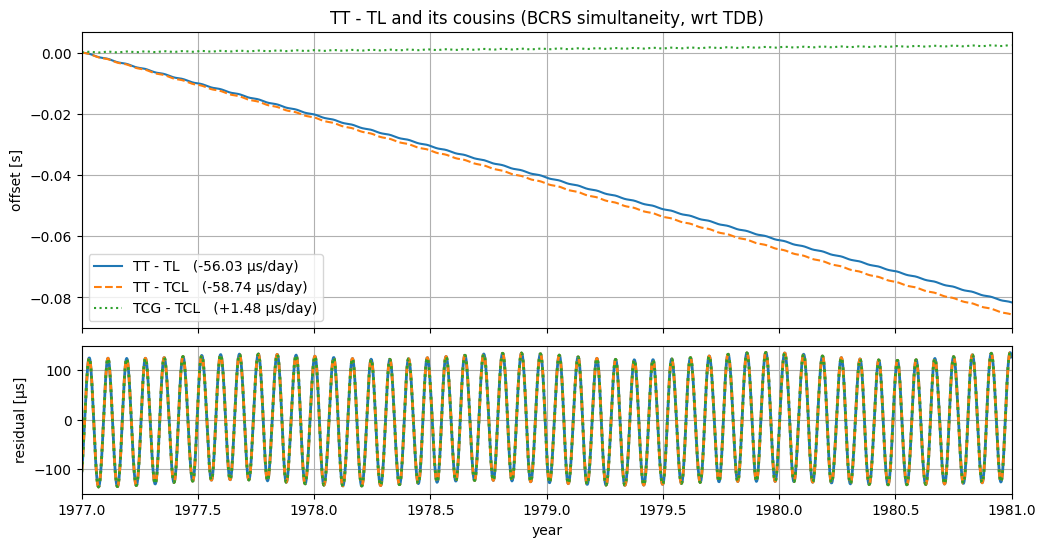

In [9]:
ce, _ = read_csv(earth_csv)
cm, _ = read_csv(moon_csv)
grid = TimeGrid(ce["JD_int"], ce["JD_frac"])
assert np.array_equal(grid.jd_int, cm["JD_int"]) and np.array_equal(grid.jd_frac, cm["JD_frac"])

WINDOW = (1977, 1977+4)   # displayed x-range: a readable 4-yr slice of the full 1977-2077 run

def days_since(g, t0):
    return (g.jd_int - t0.int_part).astype(np.float64) + (g.jd_frac - t0.frac_part)

def realized_offset(g, t0, l):
    # TX - TCX, IERS Eq. 10.1 (matches output.tt_minus_tcg_from_jdtt for l=L_G).
    return -(l / (1.0 - l)) * days_since(g, t0) * float(DAY_S)

tcg_minus_tcl = -ce["TCB_minus_TCX"] + cm["TCB_minus_TCX"]                     # worldline only
tt_minus_tl   = tcg_minus_tcl + realized_offset(grid, T0, L_G) - realized_offset(grid, T0, L_L)
tt_minus_tcl  = tcg_minus_tcl + realized_offset(grid, T0, L_G)                # realized Earth vs coord Moon

yr = yr_from_jd(grid.jd_int + grid.jd_frac)
# Top: three offsets grow at their own linear rates. Bottom: detrending removes
# the linear realization terms, so all three collapse onto one residual curve —
# the periodic part is purely the ephemeris (worldline) integral.
plot_trend_residual(yr, {"TT - TL": tt_minus_tl, "TT - TCL": tt_minus_tcl, "TCG - TCL": tcg_minus_tcl},
                    xlim=WINDOW, title="TT - TL and its cousins (BCRS simultaneity, wrt TDB)");


≈ 56 µs/day, decomposing into −60.2 (Earth geoid, $L_G$) + 2.7 (lunar surface, $L_L$) + 1.5 (worldline integrals — the TCG−TCL secular rate validated in notebook 07) µs/day. Only that last 1.5 needed an ephemeris. The bottom panel makes the structure explicit: detrending removes the two linear realization terms, so TT−TL, TT−TCL and the pure worldline TCG−TCL land on **one** residual curve (±136 µs) — every bit of periodic content comes from the ephemeris integral.

**Where is each zero?** By the IAU definitions, TT − TCG = 0 *and* TCB − TCG = 0 at the **same** event — 1977 Jan 1.0 TAI at the geocenter — which is what T0 marks. TDB is the exception: TDB − TCB = TDB0 = −65.5 µs there, and TDB − TT has no single zero, only a ≈ 0 mean. The lunar zero TL − TCL = 0 is a **free convention**: reusing T0 = 1977 (as here) lets TL join that same coincidence, so anchoring both worldline legs at 1977 makes all four terms share one zero epoch and TT − TL is genuinely zero at T0. A lunar programme could instead adopt its own origin T0_L — that only adds a constant to TL, shifting where TT − TL crosses zero; no rate and no residual would change.

## 7 · The simultaneity ambiguity

"TT − TL at epoch x" compares clocks on two worldlines — **undefined until you fix which event pair**. The chain above pairs events sharing a barycentric label (BCRS-simultaneous). Pairing events simultaneous in the *geocentric* system instead shifts the result by the boost term (`model.boost_term`; derived in notebook 07, §2), for center $C$ and target $X$:

$$\Delta_{\text{boost}} = \frac{\mathbf{v}_C\cdot\mathbf{r}_{X-C}}{c^2}, \qquad \text{Earth–Moon: } \frac{\mathbf{v}_E\cdot\mathbf{r}_{LE}}{c^2} \lesssim 136\ \mu\text{s (monthly)}.$$

That dwarfs everything else here, and cannot be recovered from the numbers — only from the `simultaneity: "TCB"` metadata stamp. A two-way link measures light times itself and needs no convention from us; only a user wanting the geocentric *picture* subtracts the boost term, computed below:

boost term: ±136.1 µs peak (monthly)


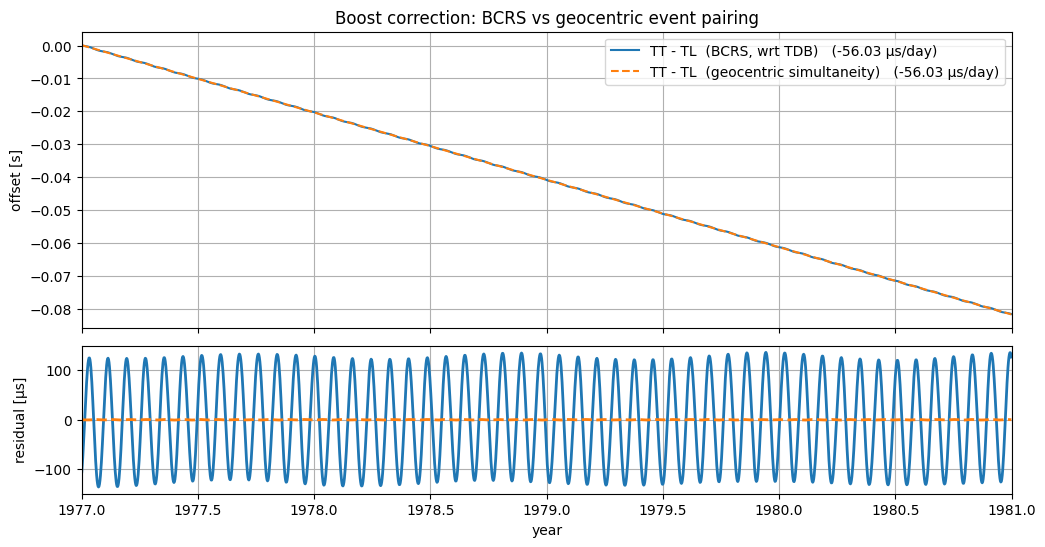

In [10]:
eph = CalcephEphem.open([str(EPH)])
boost = boost_term(eph, jd_int=grid.jd_int, jd_frac=grid.jd_frac, target=301, center=399)
eph.close()

tt_minus_tl_geo = tt_minus_tl - boost   # geocentric-simultaneity description (sign as notebook 07)
print(f"boost term: ±{np.max(np.abs(boost))*1e6:.1f} µs peak (monthly)")

# Same rate in both descriptions (the boost is periodic); the residual panel
# shows the boost correction collapsing the ±136 µs monthly term to sub-µs.
plot_trend_residual(yr, {"TT - TL  (BCRS, wrt TDB)": tt_minus_tl,
                         "TT - TL  (geocentric simultaneity)": tt_minus_tl_geo},
                    xlim=WINDOW, title="Boost correction: BCRS vs geocentric event pairing");

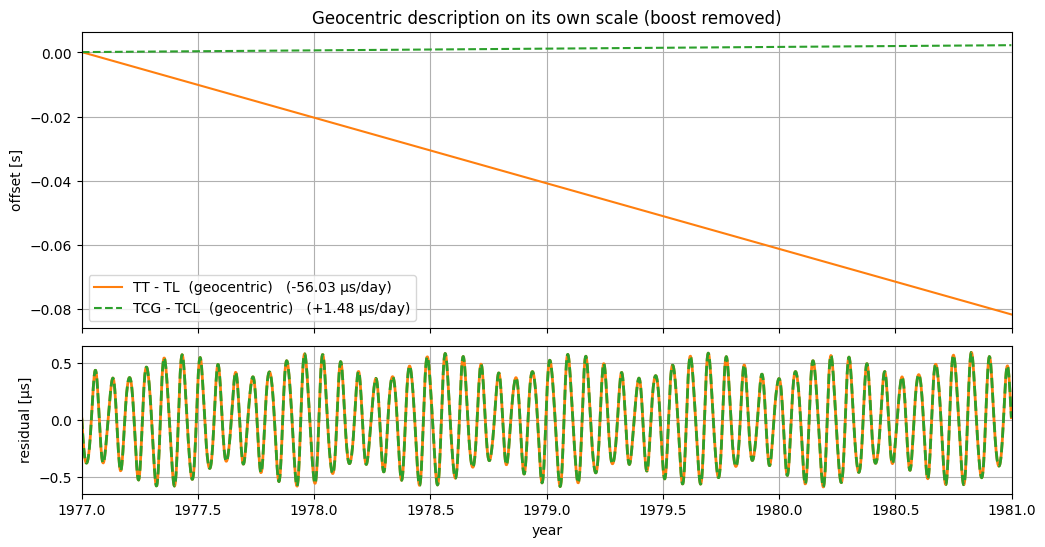

In [ ]:
# On its own scale the geocentric residual is ~200x smaller than the BCRS one
# above — this is the geocentric description of notebook 07. As in §6, TT-TL
# and the pure worldline TCG-TCL differ only by the linear realization, so
# their residuals again coincide.
# Colours match the plots above: TT-TL orange (C1), TCG-TCL green (C2).
tcg_minus_tcl_geo = tcg_minus_tcl - boost
plot_trend_residual(yr, {"TT - TL  (geocentric)": tt_minus_tl_geo,
                         "TCG - TCL  (geocentric)": tcg_minus_tcl_geo},
                    colors=["C1", "C2"], xlim=WINDOW,
                    title="Geocentric description on its own scale (boost removed)");

## 8 · The inverse view: TT − TL as a function of TL

A lunar user wants the offset against their own clock reading **TL**. The two `_tcx.asc` files can't just be subtracted — each is labeled by its *own* body's timescale (TCG vs TCL), different axes. Instead, relabel the assembled chain once: every sample is one event pair carrying all labels, so the argument change is the exact per-sample map (`model.relabel_to_tcx`; Klioner 2026; notebook 08):

$$T_k = t_k - \frac{y_k}{86400}, \qquad y = \mathrm{TDB}-\mathrm{TL} = \underbrace{(\mathrm{TDB}-\mathrm{TCB})}_{\text{IAU B3}} + \underbrace{(\mathrm{TCB}-\mathrm{TCL})}_{\text{moon leg}} + \underbrace{(\mathrm{TCL}-\mathrm{TL})}_{L_L}.$$

No iteration. 

In [12]:
tcb_minus_tdb = (float(L_B) * days_since(grid, T0) * float(DAY_S) - float(TDB0_S)) / (1.0 - float(L_B))
y = -tcb_minus_tdb + cm["TCB_minus_TCX"] - realized_offset(grid, T0, L_L)   # TDB - TL per sample
tl_grid = relabel_to_tcx(grid, y)   # grid is TDB and y = TDB - TL, so this relabels onto TL
                                    # (as notebook 08 relabels TCB with TCB - TCX onto TCX)

fit_wrt_tdb = ChebySeries.from_samples(grid.jd_int, grid.jd_frac, tt_minus_tl,
                                       granule_len=4, order=11, dist=2, npoints=10)
# same TT - TL values, now on the TL labels
fit_wrt_tl  = ChebySeries.from_samples(tl_grid.jd_int, tl_grid.jd_frac, tt_minus_tl,
                                       granule_len=4, order=11, dist=2, npoints=10)


Below, both views (wrt TDB and wrt TL) appear indistinguishable in the overview — the difference panels then reveal the ns-level structure that sets them apart. The two views are **different functions**, not a constant offset apart:

|TDB - TL| up to 2.0 s;  view difference +0.00 .. +2.00 ns


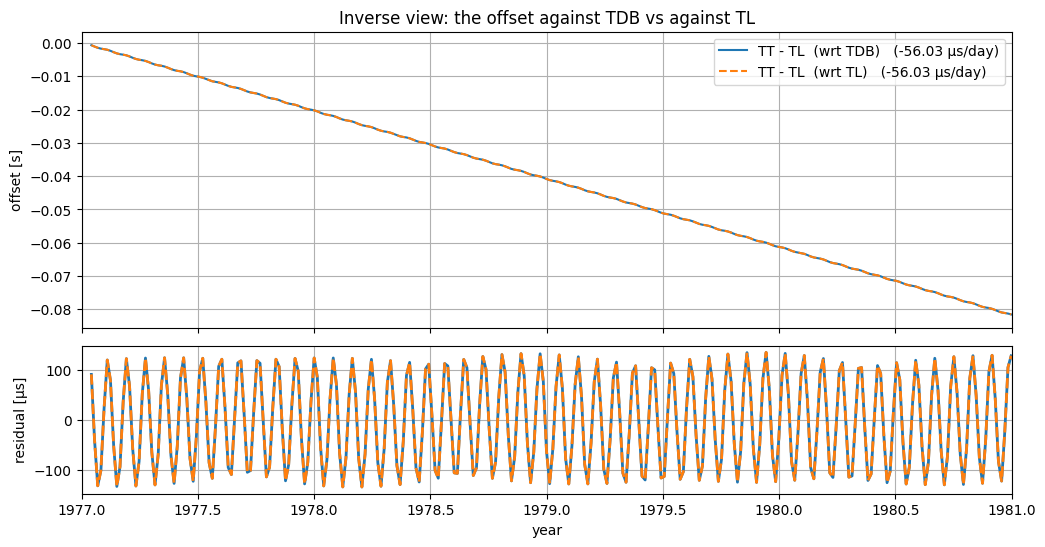

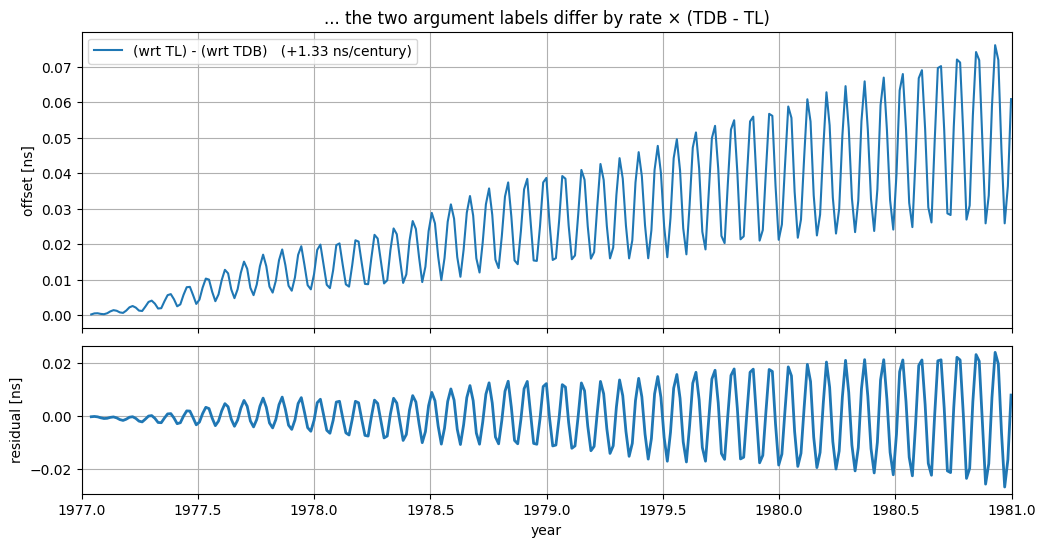

In [13]:
# Common interior epochs (avoid the fitted domain's edges), 5-day cadence.
q = jd_grid(int(grid.jd_int[0]) + 15, grid.jd_frac[0], int(grid.jd_int[-1]) - 15, grid.jd_frac[-1], 5.0)
q_yr    = yr_from_jd(q.jd_int + q.jd_frac)
val_tdb = fit_wrt_tdb.evaluate(q.jd_int, q.jd_frac)
val_tl  = fit_wrt_tl.evaluate(q.jd_int, q.jd_frac)
diff    = val_tl - val_tdb
print(f"|TDB - TL| up to {np.max(np.abs(y)):.1f} s;  view difference {diff.min()*1e9:+.2f} .. {diff.max()*1e9:+.2f} ns")

# As offsets the two views are indistinguishable (they overlap to ~2 ns) ...
plot_trend_residual(q_yr, {"TT - TL  (wrt TDB)": val_tdb, "TT - TL  (wrt TL)": val_tl},
                    xlim=WINDOW, title="Inverse view: the offset against TDB vs against TL");

# ... so their difference is the whole story — a ns-level trend + residual.
plot_trend_residual(q_yr, {"(wrt TL) - (wrt TDB)": diff},
                    trend_scale=1e9, trend_unit="ns", resid_scale=1e9, resid_unit="ns",
                    rate_scale=365.25 * 100 * 1e9, rate_unit="ns/century",
                    xlim=WINDOW, title="... the two argument labels differ by rate × (TDB - TL)");

The difference panel is ≈ rate × (TDB − TL): a couple of ns, bounded because TDB − TL itself stays within ~2 s over the century (printed above). Its residual is what survives after the linear part — the genuinely non-trivial, parameterisation-dependent piece. **Rule of thumb: irrelevant for µs sync, mandatory below ~1 ns.** With both legs anchored at 1977 the relabelled axis is conventional TL.

## 9 · What a user/agency receives

| item | content | kind |
|---|---|---|
| `nb09_earth.asc` | TCB − TCG, wrt TDB, zero at 1977 | **data** (integral) |
| `nb09_moon.asc` | TCB − TCL, wrt TDB, zero at 1977 | **data** (integral) |
| L_G, L_L, T0, L_B, TDB0 | realization + label bridge | **five constants** |
| `simultaneity: "TCB"` | the event-pairing convention (§7) | metadata |
| `*_tcx.asc` *(on request)* | offsets wrt each body's own label (§8) | data, tagged |

Two Chebyshev files and five numbers. Were TCB the common baseclock, the constants row would vanish and only the per-worldline integral — the part TEMPUS computes — would remain, each site applying its own local correction as it already must.